# ML ASSIGNMENT - B3


Given a bank customer, build a neural network-based classifier that can determine whether 
they will leave or not in the next 6 months. <br>
Dataset Description: The case study is from an open-source dataset from Kaggle. <br>
The dataset contains 10,000 sample points with 14 distinct features such as 
CustomerId, CreditScore, Geography, Gender, Age, Tenure, Balance, etc. 

Link to the Kaggle project: <br>
https://www.kaggle.com/barelydedicated/bank-customer-churn-modeling

Perform following steps: 
1. Read the dataset. 
2. Distinguish the feature and target set and divide the data set into training and test sets. 
3. Normalize the train and test data.  
4. Initialize and build the model. Identify the points of improvement and implement the same.  
5. Print the accuracy score and confusion matrix (5 points). 

### 1) Import libraries

In [161]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

### 2) Load Dataset

In [162]:
df = pd.read_csv("Churn_Modelling.csv")

The dataset contains 10,000 customers.
Target column: Exited
- 0 → Customer stays with the bank
- 1 → Customer leaves the bank

In [163]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [164]:
# Dataset shape
df.shape

(10000, 14)

In [165]:
print("\nMissing Values:")
df.isnull().sum()


Missing Values:


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [166]:
# Check datatypes
df.dtypes

RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [167]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [168]:
# Statistical Summary
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [169]:
print("\nTarget Distribution:\n", df["Exited"].value_counts())


Target Distribution:
 Exited
0    7963
1    2037
Name: count, dtype: int64


### 3) Separate features and target, and split the dataset
Remove the RowNumber, CustomerId, and Surname columns

In [170]:
# Separate features and target
X = df.drop(["RowNumber", "CustomerId", "Surname", "Exited"], axis=1)
y = df["Exited"]

In [171]:
# Convert categorical columns into numeric columns
X = pd.get_dummies(X, columns=["Geography", "Gender"], dtype=int)

In [172]:
# Split into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### 4) Normalize training and testing data

In [173]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### 5) Initialize and build the neural network
We create a simple ANN with two hidden layers and one output layer.

In [174]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_36 (Dense)                     │ (None, 16)                  │             224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_37 (Dense)                     │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_38 (Dense)                     │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

Explanation:
- Dense(16) → First hidden layer with 16 neurons
- Dense(8) → Second hidden layer with 8 neurons
- relu → Activation function for hidden layers
- sigmoid → Produces a probability between 0 and 1
- adam → Optimizer
- binary_crossentropy → Loss function for binary classification

In [175]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7898 - loss: 0.5117 - val_accuracy: 0.8125 - val_loss: 0.4483
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8070 - loss: 0.4455 - val_accuracy: 0.8256 - val_loss: 0.4231
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8150 - loss: 0.4314 - val_accuracy: 0.8319 - val_loss: 0.4158
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8195 - loss: 0.4223 - val_accuracy: 0.8244 - val_loss: 0.4136
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8248 - loss: 0.4161 - val_accuracy: 0.8300 - val_loss: 0.4073
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8281 - loss: 0.4105 - val_accuracy: 0.8306 - val_loss: 0.4049
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8309 - loss: 0.4050 - val_accuracy: 0.8344 - val_loss: 0.3999
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8338 - loss: 0.4003 - val_accuracy: 0.

### 6) Identify improvements and implement them
We can improve the model by adding a Dropout layer to reduce overfitting and EarlyStopping to stop training when validation loss stops improving.

In [176]:
improved_model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

improved_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

improved_history = improved_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7420 - loss: 0.5377 - val_accuracy: 0.8006 - val_loss: 0.4489
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8017 - loss: 0.4455 - val_accuracy: 0.8269 - val_loss: 0.4143
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8169 - loss: 0.4257 - val_accuracy: 0.8331 - val_loss: 0.3965
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8303 - loss: 0.4057 - val_accuracy: 0.8469 - val_loss: 0.3814
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8375 - loss: 0.3927 - val_accuracy: 0.8469 - val_loss: 0.3715
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8402 - loss: 0.3822 - val_accuracy: 0.8506 - val_loss: 0.3644
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8406 - loss: 0.3764 - val_accuracy: 0.8475 - val_loss: 0.3581
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8434 - loss: 0.3663 - val_accuracy: 0.

### 7) Print accuracy score and confusion matrix

In [177]:
# Predict using model
y_pred_improved = (improved_model.predict(X_test) > 0.5).astype(int).ravel()

# Accuracy
print("Improved Model Accuracy:", accuracy_score(y_test, y_pred_improved))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_improved)

print("\nConfusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_improved, zero_division=0))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Improved Model Accuracy: 0.861

Confusion Matrix:
[[1552   55]
 [ 223  170]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1607
           1       0.76      0.43      0.55       393

    accuracy                           0.86      2000
   macro avg       0.81      0.70      0.73      2000
weighted avg       0.85      0.86      0.85      2000



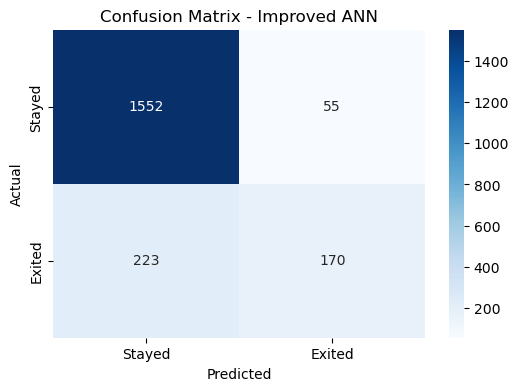

In [178]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Exited"],
    yticklabels=["Stayed", "Exited"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Improved ANN")
plt.show()

### 8) Predict a single customer's churn

In [179]:
# Predict the first customer in the test dataset
prediction = improved_model.predict(X_test[:1])[0][0]

print("Churn Probability:", round(float(prediction), 4))

if prediction > 0.5:
    print("Prediction: Customer will leave the bank")
else:
    print("Prediction: Customer will stay with the bank")

print("Actual Result:", "Exited" if y_test.iloc[0] == 1 else "Stayed")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
Churn Probability: 0.0546
Prediction: Customer will stay with the bank
Actual Result: Stayed
